# Email and SMS exploration

In [45]:
from pathlib import Path
from collections import Counter

import pandas as pd
import matplotlib.pyplot as plt

# Assuming the notebook runs from ml/notebooks/
DATA_DIR = Path("../data/raw")

email = pd.read_csv(DATA_DIR / "spam_ham_email.csv")
sms = pd.read_csv(DATA_DIR / "spam_ham_sms.csv", encoding="latin-1")

print("Email shape:", email.shape)
print("SMS shape:", sms.shape)

display(email.head())
display(sms.head())

Email shape: (5171, 4)
SMS shape: (5572, 5)


,Unnamed: 0,label,text,label_num
0,605,ham,Subject: enron methanol ; meter # : 988291\r\n...,0
1,2349,ham,"Subject: hpl nom for january 9 , 2001\r\n( see...",0
2,3624,ham,"Subject: neon retreat\r\nho ho ho , we ' re ar...",0
3,4685,spam,"Subject: photoshop , windows , office . cheap ...",1
4,2030,ham,Subject: re : indian springs\r\nthis deal is t...,0


,v1,v2,Unnamed: 2,Unnamed: 3,Unnamed: 4
0,ham,"Go until jurong point, crazy.. Available only ...",NaN,NaN,NaN
1,ham,Ok lar... Joking wif u oni...,NaN,NaN,NaN
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...,NaN,NaN,NaN
3,ham,U dun say so early hor... U c already then say...,NaN,NaN,NaN
4,ham,"Nah I don't think he goes to usf, he lives aro...",NaN,NaN,NaN


## Standardize and combine datasets

In [46]:
# Standardize email dataset
email = email[["text", "label"]].copy()
email["source"] = "email"

# Standardize SMS dataset
sms = sms[["v2", "v1"]].copy()
sms.columns = ["text", "label"]
sms["source"] = "sms"

# Combine datasets
df = pd.concat([email, sms], ignore_index=True)

# Feature for exploratory analysis
df["word_count"] = df["text"].str.split().str.len()

display(df.head())
print("Combined shape:", df.shape)

,text,label,source,word_count
0,Subject: enron methanol ; meter # : 988291\r\n...,ham,email,67
1,"Subject: hpl nom for january 9 , 2001\r\n( see...",ham,email,23
2,"Subject: neon retreat\r\nho ho ho , we ' re ar...",ham,email,550
3,"Subject: photoshop , windows , office . cheap ...",spam,email,48
4,Subject: re : indian springs\r\nthis deal is t...,ham,email,70


Combined shape: (10743, 4)


## Check data quality

In [47]:
print("Missing values:")
print(df.isnull().sum())

print("\nDuplicate messages:")
print(df.duplicated(subset=["text"]).sum())

print("\nConflicting labels:")
conflicts = df.groupby("text")["label"].nunique()
print((conflicts > 1).sum())

Missing values:
text          0
label         0
source        0
word_count    0
dtype: int64

Duplicate messages:
581

Conflicting labels:
0


## Explore class distribution

Class distribution:
label
ham     8497
spam    2246
Name: count, dtype: int64

Class distribution (%):
label
ham     79.093363
spam    20.906637
Name: proportion, dtype: float64


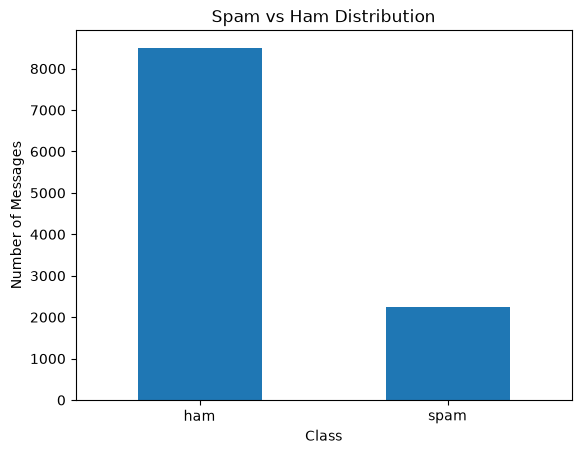

In [48]:
print("Class distribution:")
print(df["label"].value_counts())

print("\nClass distribution (%):")
print(df["label"].value_counts(normalize=True) * 100)

df["label"].value_counts().plot(
    kind="bar",
    title="Spam vs Ham Distribution"
)

plt.xlabel("Class")
plt.ylabel("Number of Messages")
plt.xticks(rotation=0)
plt.show()

## Explore message lengths

Average word count by class:
label
ham     105.390726
spam    164.158059
Name: word_count, dtype: float64


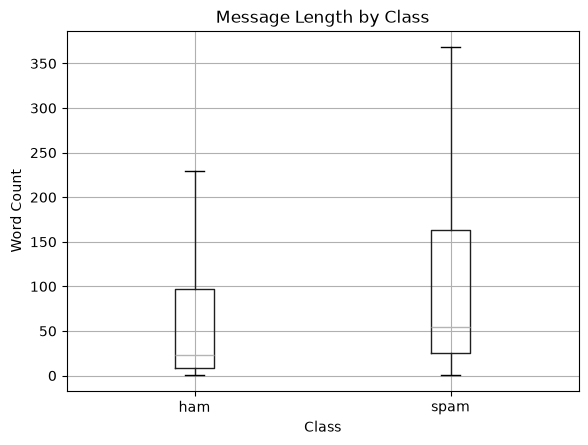

In [49]:
print("Average word count by class:")
print(df.groupby("label")["word_count"].mean())

df.boxplot(
    column="word_count",
    by="label",
    showfliers=False
)

plt.title("Message Length by Class")
plt.suptitle("")
plt.xlabel("Class")
plt.ylabel("Word Count")
plt.show()

## Most common words in spam and ham

In [50]:
def most_common_words(texts, n=20):
    words = " ".join(texts.astype(str)).lower().split()
    return Counter(words).most_common(n)


spam_words = most_common_words(
    df.loc[df["label"] == "spam", "text"]
)

ham_words = most_common_words(
    df.loc[df["label"] == "ham", "text"]
)

print("Most common spam words:")
print(spam_words)

print("\nMost common ham words:")
print(ham_words)

Most common spam words:
[('.', 19502), (',', 11228), ('-', 7996), ('the', 7458), ('to', 5842), ('/', 5708), ('and', 5025), (':', 4612), ('of', 4585), ('a', 4160), ('in', 3198), ('=', 3096), ('you', 3046), ('for', 2724), ('!', 2466), ('is', 2408), ('this', 2369), ('your', 2209), ('?', 1934), ("'", 1762)]

Most common ham words:
[('-', 77815), ('/', 37142), ('.', 35414), (',', 29442), (':', 20502), ('the', 19472), ('to', 16716), ('ect', 13897), ('@', 12174), ('and', 8757), ('for', 8478), ('i', 7413), ('hou', 7281), ('a', 7072), ('you', 7030), ('enron', 6555), ('on', 6428), ('of', 6195), ("'", 5786), ('is', 5616)]


## Plotted results

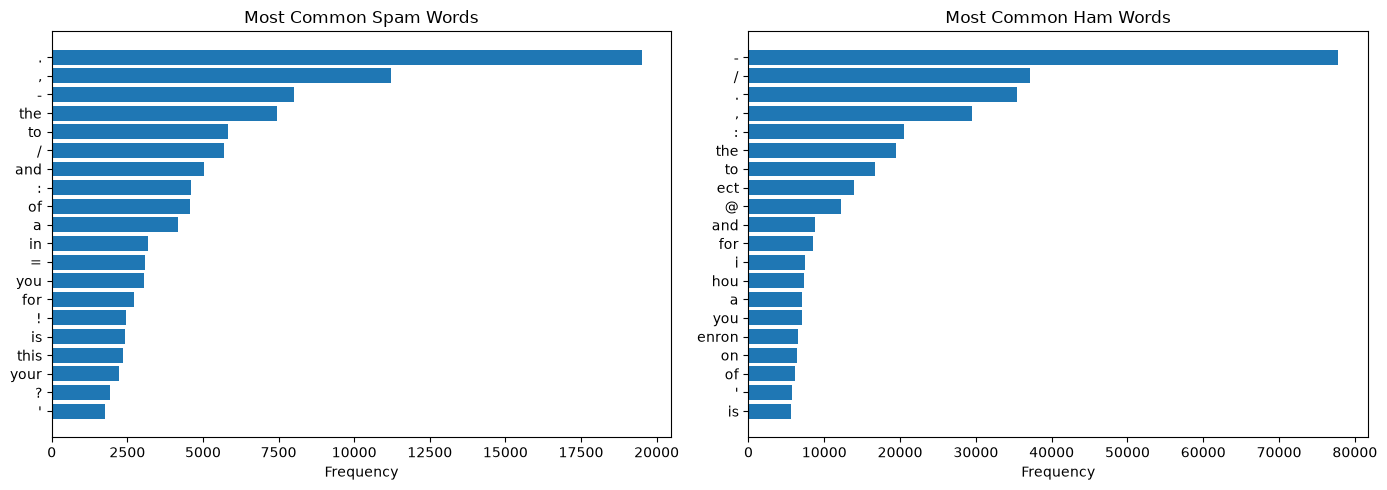

In [51]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, word_counts, title in zip(
    axes,
    [spam_words, ham_words],
    ["Most Common Spam Words", "Most Common Ham Words"]
):
    words, counts = zip(*word_counts)

    ax.barh(words[::-1], counts[::-1])
    ax.set_title(title)
    ax.set_xlabel("Frequency")

plt.tight_layout()
plt.show()

## Compare email and SMS datasets

### Dataset sizes

Messages by source:
source
sms      5572
email    5171
Name: count, dtype: int64


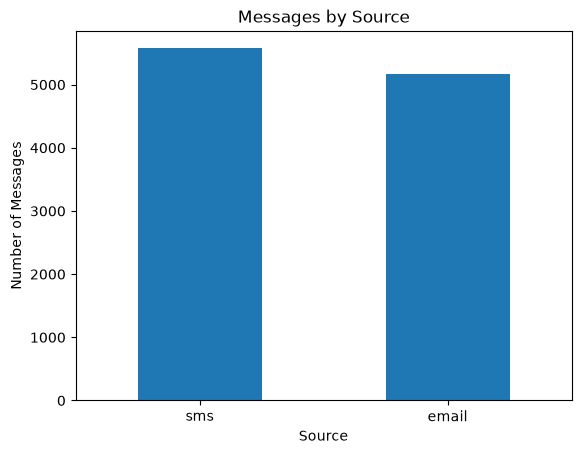

In [52]:
print("Messages by source:")
print(df["source"].value_counts())

df["source"].value_counts().plot(
    kind="bar",
    title="Messages by Source"
)

plt.xlabel("Source")
plt.ylabel("Number of Messages")
plt.xticks(rotation=0)
plt.show()

### Spam distribution by source

Class counts by source:
label    ham  spam
source            
email   3672  1499
sms     4825   747

Class proportions by source:
label        ham      spam
source                    
email   0.710114  0.289886
sms     0.865937  0.134063


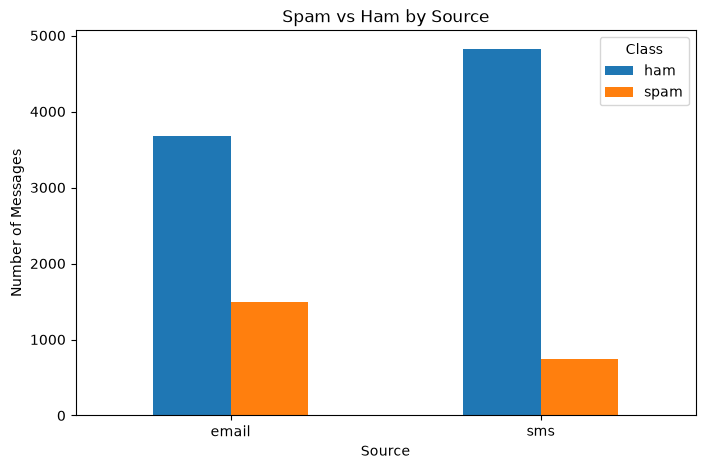

In [53]:
print("Class counts by source:")
print(pd.crosstab(df["source"], df["label"]))

print("\nClass proportions by source:")
print(
    pd.crosstab(
        df["source"],
        df["label"],
        normalize="index"
    )
)

pd.crosstab(df["source"], df["label"]).plot(
    kind="bar",
    figsize=(8, 5),
    title="Spam vs Ham by Source"
)

plt.xlabel("Source")
plt.ylabel("Number of Messages")
plt.xticks(rotation=0)
plt.legend(title="Class")
plt.show()

### Message lengths by source

Average word count by source:
source
email    227.783601
sms       15.494436
Name: word_count, dtype: float64


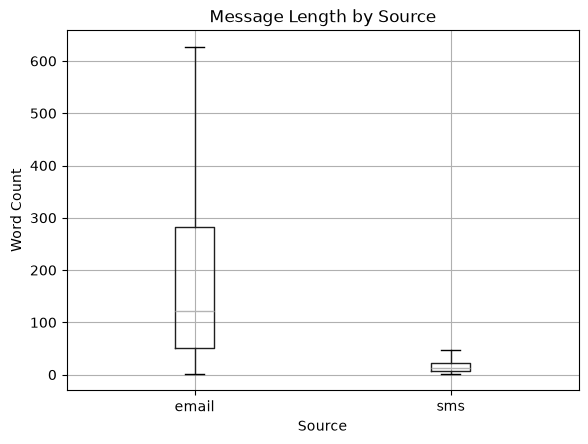

In [54]:
print("Average word count by source:")
print(df.groupby("source")["word_count"].mean())

df.boxplot(
    column="word_count",
    by="source",
    showfliers=False
)

plt.title("Message Length by Source")
plt.suptitle("")
plt.xlabel("Source")
plt.ylabel("Word Count")
plt.show()

## Dataset summary

In [55]:
print("=== DATASET SUMMARY ===")

print(f"Total messages: {len(df)}")

print("\nMessages by source:")
print(df["source"].value_counts())

print("\nClass distribution (%):")
print(df["label"].value_counts(normalize=True) * 100)

print("\nMissing values:")
print(df.isnull().sum())

print("\nDuplicate messages:")
print(df.duplicated(subset=["text"]).sum())

print("\nConflicting labels:")
print(
    df.groupby("text")["label"]
    .nunique()
    .gt(1)
    .sum()
)

print("\nAverage word count by class:")
print(df.groupby("label")["word_count"].mean())

print("\nAverage word count by source:")
print(df.groupby("source")["word_count"].mean())

print("\nSpam percentage by source:")
print(
    df.groupby("source")["label"]
    .apply(lambda labels: (labels == "spam").mean() * 100)
)

=== DATASET SUMMARY ===
Total messages: 10743

Messages by source:
source
sms      5572
email    5171
Name: count, dtype: int64

Class distribution (%):
label
ham     79.093363
spam    20.906637
Name: proportion, dtype: float64

Missing values:
text          0
label         0
source        0
word_count    0
dtype: int64

Duplicate messages:
581

Conflicting labels:
0

Average word count by class:
label
ham     105.390726
spam    164.158059
Name: word_count, dtype: float64

Average word count by source:
source
email    227.783601
sms       15.494436
Name: word_count, dtype: float64

Spam percentage by source:
source
email    28.988590
sms      13.406317
Name: label, dtype: float64


## EDA Summary

### Dataset Overview
- Combined 5,171 emails and 5,572 SMS messages.
- Total of 10,743 messages.
- Approximately 79.1% ham and 20.9% spam.

### Data Quality
- No missing values.
- No conflicting labels.
- Found 581 duplicate rows based on message text alone. Preprocessing removes duplicates using both message text and source.

### Key Observations
- Spam messages contain more words on average than ham messages.
- Emails are substantially longer than SMS messages.
- Approximately 29.0% of emails are spam, compared with 13.4% of SMS messages.
- Differences in message length between spam and ham may be influenced by the substantially different lengths and spam rates of email and SMS messages.

### Implications for Model Training
- Class imbalance: Approximately 79% of messages are ham, so accuracy alone is insufficient.
- Text representation: Use **TF-IDF** to convert message text into numerical features.
- Model selection: Compare **DummyClassifier, Multinomial Naive Bayes, Logistic Regression, and Linear SVM** using cross-validation.
- Duplicate messages: Remove duplicate messages and use group-aware splitting to prevent identical text from appearing in both training and testing sets.
- Dataset differences: Emails are significantly longer and have higher spam rates than SMS messages. Include source as a feature and evaluate performance separately for each source.
- Model evaluation: Evaluate spam **precision, recall, F1-score, ROC-AUC, and accuracy**, with particular attention to false positives.